# 04 — Perfiles de contratación y valores atípicos

Comparamos volumen y composición de categorías en el corte descriptivo 2023–2024. El ruido y la distancia al centroide describen perfiles en este conjunto; **no prueban irregularidades**. Este cuaderno lee resultados publicados y no los modifica.


In [3]:
# Carga resultados ya calculados; esta celda no vuelve a entrenar modelos.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Encuentra la raíz tanto si el notebook abre desde la raíz como desde notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / "artifacts").exists():
    ROOT = ROOT.parent
result = ROOT / "artifacts" / "clustering"
# _SUCCESS confirma que la publicación terminó.
if not (result / "_SUCCESS").is_file():
    raise FileNotFoundError("Construya los resultados según docs/ComandosEjecutarOrdenReplica.md")
# Los metadatos guardan parámetros, selección y huellas de la corrida.
meta = json.loads((result / "_metadata.json").read_text(encoding="utf-8"))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.features.build_part1 import directory_fingerprint  # noqa: E402

# Verifica que los features actuales sean los mismos usados para clustering.
part1 = ROOT / "data" / "processed" / "part1"
if (
    not (part1 / "_SUCCESS").is_file()
    or directory_fingerprint(part1) != meta["source"]["part1_sha256"]
):
    raise ValueError("Resultados desactualizados: vuelva a ejecutar el clustering.")
# Carga features, asignaciones, métricas y perfiles publicados.
features = pd.read_parquet(result / "features.parquet")
assignments = pd.read_parquet(result / "assignments.parquet")
km = pd.read_parquet(result / "kmeans_metrics.parquet")
hd = pd.read_parquet(result / "hdbscan_metrics.parquet")
profiles = pd.read_parquet(result / "profiles.parquet")
print(
    "Ventana:",
    meta["source_window"],
    "| Entidades:",
    meta["input_rows"],
    "| Adjudicaciones:",
    meta["source_awards"],
)


Ventana: {'start_award_year': 2023, 'end_award_year': 2024} | Entidades: 2756 | Adjudicaciones: 81724


El cuaderno no vuelve a entrenar modelos: abre resultados ya calculados. La ventana 2023–2024 contiene 2 756 entidades y 81 724 adjudicaciones, que son la población analizada en las secciones siguientes.


## 1. Referencia y datos

Los cuantiles resumen el universo observado. Las proporciones corresponden a categorías amplias; tres proporciones suman uno y no son variables independientes. Los valores se escalaron en la ventana completa para este estudio descriptivo.


,award_count,fraction_0,fraction_1,fraction_2
count,2756.000000,2756.000000,2756.000000,2756.000000
mean,29.653120,0.460207,0.402014,0.137779
std,80.404979,0.313913,0.303061,0.223697
min,1.000000,0.000000,0.000000,0.000000
25%,4.000000,0.200000,0.166667,0.000000
50%,11.000000,0.473684,0.344371,0.000000
75%,29.000000,0.703468,0.586207,0.200000
max,2105.000000,1.000000,1.000000,1.000000


Vectores originales distintos: 1421


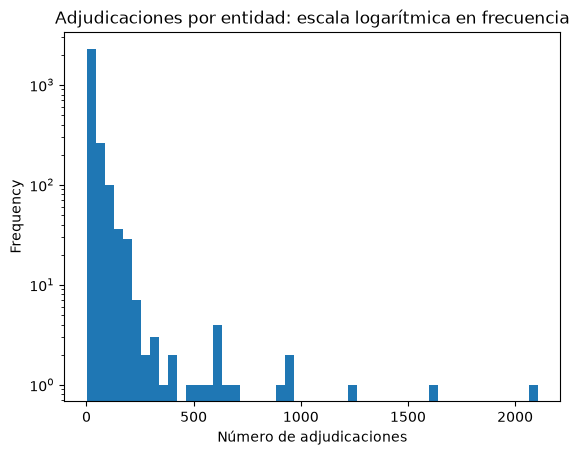

In [4]:
# Resume las variables originales antes de agrupar entidades.
display(features[["award_count", "fraction_0", "fraction_1", "fraction_2"]].describe())
# Cuenta perfiles repetidos: entidades distintas pueden tener las mismas cuatro variables.
print(
    "Vectores originales distintos:",
    len(features[["log_award_count", "fraction_0", "fraction_1", "fraction_2"]].drop_duplicates()),
)
# El histograma muestra cuánto varía el número de adjudicaciones por entidad.
# logy=True permite ver valores frecuentes y poco frecuentes en la misma figura.
features["award_count"].plot.hist(
    bins=50, logy=True, title="Adjudicaciones por entidad: escala logarítmica en frecuencia"
)
plt.xlabel("Número de adjudicaciones")
plt.show()


La mitad de las entidades tiene 11 adjudicaciones o menos, pero algunas llegan a 2105 y esa diferencia grande explica por qué se usa el logaritmo del volumen antes de agrupar.

Hay 1421 perfiles de variables distintos para 2756 entidades: varias entidades comparten exactamente el mismo perfil numérico. Esto ayuda a interpretar grupos densos y repetidos.


## 2. KMeans++

La opción provisional maximiza la silueta de una muestra de hasta 1 500 entidades en la variante ponderada, descartando grupos menores al 1 % o a 15 entidades. Revisar también tamaños, estabilidad y escala: la regla numérica no demuestra que exista una única tipología correcta.


,variant,k,inertia,silhouette,min_cluster_size,max_cluster_size
0,standard,2,7595.639852,0.305589,1313,1443
1,standard,3,5164.253896,0.368054,442,1325
2,standard,4,3907.556713,0.341076,449,836
3,standard,5,3267.045592,0.326406,296,747
4,standard,6,2727.216634,0.342163,296,691
5,standard,7,2305.328598,0.354384,113,578
6,standard,8,2045.248842,0.364455,98,487
7,weighted,2,3602.991064,0.301580,1169,1587
8,weighted,3,2742.539678,0.308468,867,987
9,weighted,4,2031.291997,0.358785,395,968


Selección provisional: {'variant': 'weighted', 'k': 4, 'inertia': 2031.2919969852521, 'silhouette': 0.35878549945975463, 'min_cluster_size': 395, 'max_cluster_size': 968}


,method,label,entities,median_awards,median_goods,median_services,median_works
47,kmeans,0,968,41.0,0.518833,0.388889,0.017243
48,kmeans,1,395,5.0,0.166667,0.250000,0.500000
49,kmeans,2,537,6.0,0.000000,0.909091,0.000000
50,kmeans,3,856,6.0,0.724747,0.200000,0.000000


,method,seed,sample_size,ari_vs_full_on_sample
0,kmeans,1,2204,0.991948
1,kmeans,7,2204,0.987133
2,kmeans,21,2204,0.991592
3,kmeans,42,2204,0.988596
4,kmeans,100,2204,0.936205


,method,config,ari_between_scalings,both_assigned_count,ari_both_assigned
0,kmeans,4,0.755908,NaN,NaN
1,hdbscan,15:5,0.630494,1313.0,0.568509


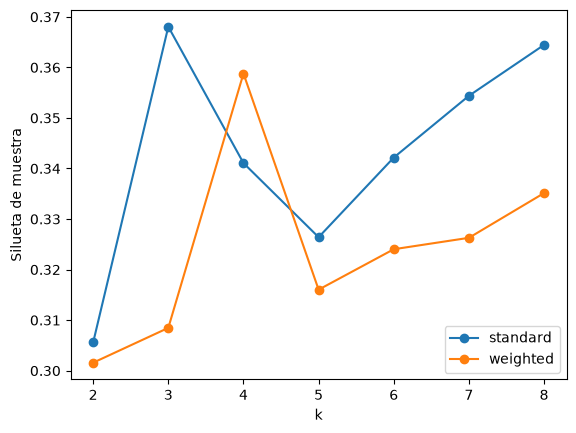

In [ ]:
# Una fila por configuración de KMeans: variante de escala y número de grupos k.
display(km.sort_values(["variant", "k"]))
# standard: mismo peso para volumen y cada proporción.
# weighted: reduce cada proporción por 1/sqrt(3) para que las tres juntas no dominen el volumen.
# inertia: suma de distancias a centroides; baja al aumentar k, por eso no decide sola.
# silhouette: separación y compactación de grupos; cerca de 1 es mejor, cerca de 0 hay mezcla.
# min_cluster_size y max_cluster_size: tamaños del grupo menor y mayor de cada solución.

print("Selección provisional:", meta["kmeans_selected"])
# Resume la solución elegida: weighted, k=4 y silueta 0.3588.
# Sus grupos van de 395 a 968 entidades, por lo que ninguno quedó demasiado pequeño.

# Describe los cuatro grupos elegidos; label solo es un número técnico.
display(profiles[profiles.method == "kmeans"].sort_values("label"))
# entities: entidades del grupo. median_awards: mediana de adjudicaciones por entidad.
# median_goods, median_services y median_works: proporción mediana de cada categoría.

# Repite KMeans k=4 sobre cinco muestras aleatorias del 80 % de las entidades.
display(pd.DataFrame(meta["stability"]))
# ari_vs_full_on_sample compara cada muestra con la solución completa; cerca de 1 es alto acuerdo.

# Mide cuánto cambian las etiquetas al usar standard o weighted.
display(pd.DataFrame(meta["scaling_comparison"]))
# Para KMeans, ari_between_scalings cerca de 1 significaría que la escala casi no cambia los grupos.

# El gráfico compara la silueta para cada k y para las dos escalas.
# En weighted el punto más alto es k=4; por eso se seleccionó esa configuración.
for name, group in km.groupby("variant"):
    plt.plot(group.k, group.silhouette, marker="o", label=name)
plt.xlabel("k: número de grupos")
plt.ylabel("Silueta de muestra")
plt.legend()
plt.show()


Se prueba `k` entre 2 y 8 con dos escalas seleccionamos **weighted, k = 4** porque obtuvo la mayor silhouette dentro de la variante definida y ninguno de sus grupos es demasiado pequeño: van de 395 a 968 entidades.

Los cuatro perfiles resumen patrones de volumen y de proporción de bienes, servicios u obras. Las etiquetas 0, 1, 2 y 3 solo son nombres técnicos.

La estabilidad cercana a 1 indica que KMeans reproduce casi los mismos grupos al tomar muestras. Aun así, la comparación de escalas recuerda que el resultado depende de cómo se ponderan las variables.


## 3. HDBSCAN y anomalías

La silueta de HDBSCAN excluye ruido y debe leerse junto con cobertura. La selección provisional requiere al menos dos grupos y cobertura de 50 %. Revisamos también los vectores idénticos dentro de cada grupo: muchas entidades con características iguales pueden formar grupos densos sin que ello indique un mercado real.


In [7]:
# Cada fila prueba una configuración de HDBSCAN en una escala determinada.
display(hd.sort_values(["variant", "min_cluster_size", "min_samples"]))
# min_cluster_size: tamaño mínimo de un grupo. min_samples: exigencia de densidad.
# groups: grupos detectados. noise_fraction: proporción sin grupo.
# silhouette_assigned solo mide entidades asignadas, por eso no se compara directamente con KMeans.
print("Selección provisional:", meta["hdbscan_selected"])

# Conserva solo las asignaciones elegidas y agrega sus variables originales.
selected = assignments[assignments.selected].merge(features, on="entity_id", validate="many_to_one")
density = selected[(selected.method == "hdbscan") & (selected.label >= 0)]
dims = ["log_award_count", "fraction_0", "fraction_1", "fraction_2"]
if not density.empty:
    # Cuenta perfiles distintos dentro de cada grupo HDBSCAN.
    distinct = density.groupby("label", group_keys=False)[dims].apply(
        lambda x: len(x.drop_duplicates())
    )
    print("Grupos con un único vector distinto:", int((distinct == 1).sum()), "/", len(distinct))
    print("Entidades en esos grupos:", int(density.label.isin(distinct[distinct == 1].index).sum()))
# Compara cuántas entidades asignó cada método y cuántas marcó para revisión.
display(
    selected.groupby("method").agg(
        entidades=("entity_id", "size"), candidatos=("outlier_candidate", "sum")
    )
)
# Muestra ejemplos de señales extremas; son candidatos de revisión, no acusaciones.
display(
    selected[selected.outlier_candidate][
        ["entity_id", "method", "label", "award_count", "fraction_0", "fraction_1", "fraction_2"]
    ].head(30)
)


,variant,min_cluster_size,min_samples,groups,noise_count,noise_fraction,coverage,silhouette_assigned,mean_cluster_persistence
0,standard,15,5,43,1177,0.427068,0.572932,0.475187,1.0
1,standard,15,10,34,1252,0.454282,0.545718,0.501003,1.0
2,standard,30,5,14,1459,0.529390,0.470610,0.306352,1.0
3,standard,30,10,10,1407,0.510522,0.489478,0.378221,1.0
4,standard,60,5,4,542,0.196662,0.803338,0.183158,1.0
5,standard,60,10,6,1488,0.539913,0.460087,0.360200,1.0
6,weighted,15,5,46,1348,0.489115,0.510885,0.659929,1.0
7,weighted,15,10,34,1294,0.469521,0.530479,0.562689,1.0
8,weighted,30,5,8,479,0.173803,0.826197,0.226612,1.0
9,weighted,30,10,8,800,0.290276,0.709724,0.254946,1.0


Selección provisional: {'variant': 'weighted', 'min_cluster_size': 15, 'min_samples': 5, 'groups': 46, 'noise_count': 1348, 'noise_fraction': 0.48911465892597966, 'coverage': 0.5108853410740203, 'silhouette_assigned': 0.6599288855376496, 'mean_cluster_persistence': 1.0}
Grupos con un único vector distinto: 21 / 46
Entidades en esos grupos: 641


,entidades,candidatos
method,,
hdbscan,2756,1348
kmeans,2756,29


,entity_id,method,label,award_count,fraction_0,fraction_1,fraction_2
30,PE-CONSUCODE-1012,kmeans,3,1,1.000000,0.000000,0.000000
92,PE-CONSUCODE-10219,kmeans,3,23,1.000000,0.000000,0.000000
99,PE-CONSUCODE-10247,kmeans,0,1632,0.718750,0.281250,0.000000
182,PE-CONSUCODE-10413,kmeans,3,1,1.000000,0.000000,0.000000
184,PE-CONSUCODE-10417,kmeans,3,1,1.000000,0.000000,0.000000
259,PE-CONSUCODE-10493,kmeans,3,1,1.000000,0.000000,0.000000
359,PE-CONSUCODE-10604,kmeans,3,1,1.000000,0.000000,0.000000
382,PE-CONSUCODE-1070,kmeans,3,1,1.000000,0.000000,0.000000
384,PE-CONSUCODE-1073,kmeans,1,1,0.000000,0.000000,1.000000
385,PE-CONSUCODE-1074,kmeans,3,1,1.000000,0.000000,0.000000


### Aportacion de HDBSCAN

HDBSCAN busca zonas densas y deja sin grupo los casos que no encajan claramente. En la configuración elegida asigna grupo a cerca de la mitad de las entidades y marca el resto como ruido.

El ruido es un **candidato** para revisar, no una anomalía confirmada. Además, varios grupos contienen un único perfil repetido; por ello HDBSCAN describe densidades, pero no debe usarse solo para concluir comportamientos inusuales.


## 4. Referencia por volumen y coincidencia de señales

Comparamos los grupos con cuatro tramos definidos por los cuartiles del número de adjudicaciones. Los empates permanecen juntos y pueden reducir el número de tramos; esto no es otro modelo. La intersección de las señales de KMeans y HDBSCAN se muestra en el mismo universo, sin convertirla en una tasa de irregularidad.

In [8]:
import numpy as np

# Divide entidades en cuatro tramos de volumen para comparar grupos con una referencia simple.
baseline = features.copy()
baseline["volume_band"] = pd.qcut(baseline.award_count, q=4, duplicates="drop").astype(str)
k_selected = selected[selected.method == "kmeans"].copy()
h_selected = selected[selected.method == "hdbscan"].copy()
if not k_selected.empty:
    volume_compare = k_selected.merge(baseline[["entity_id", "volume_band"]], on="entity_id")
    # Indica cuántas entidades de cada grupo KMeans caen en cada tramo de volumen.
    display(pd.crosstab(volume_compare.label, volume_compare.volume_band))
    # Muestra percentiles de volumen y composición dentro de cada grupo KMeans.
    display(
        volume_compare.groupby("label")[
            ["award_count", "fraction_0", "fraction_1", "fraction_2"]
        ].quantile([0.25, 0.5, 0.75])
    )
if not k_selected.empty and not h_selected.empty:
    flags = k_selected[["entity_id", "outlier_candidate"]].merge(
        h_selected[["entity_id", "outlier_candidate"]], on="entity_id", suffixes=("_k", "_h")
    )
    # Cruza señales de KMeans y HDBSCAN para ver cuántas coinciden.
    display(pd.crosstab(flags.outlier_candidate_k, flags.outlier_candidate_h))
    # Enseña las cinco mayores distancias a su centroide KMeans.
    examples = k_selected[k_selected.outlier_candidate].sort_values("distance", ascending=False)
    display(
        examples[
            [
                "entity_id",
                "label",
                "distance",
                "award_count",
                "fraction_0",
                "fraction_1",
                "fraction_2",
            ]
        ].head(5)
    )


volume_band,"(0.999, 4.0]","(11.0, 29.0]","(29.0, 2105.0]","(4.0, 11.0]"
label,,,,
0,0,296,672,0
1,185,76,2,132
2,237,128,3,169
3,307,185,0,364


award_count  fraction_0  fraction_1  fraction_2
label                                                      
0     0.25        26.00    0.352941    0.241379    0.000000
      0.50        41.00    0.518833    0.388889    0.017243
      0.75        74.25    0.703468    0.555556    0.100000
1     0.25         2.00    0.000000    0.000000    0.424812
      0.50         5.00    0.166667    0.250000    0.500000
      0.75        10.00    0.333333    0.400000    0.666667
2     0.25         3.00    0.000000    0.666667    0.000000
      0.50         6.00    0.000000    0.909091    0.000000
      0.75        11.00    0.250000    1.000000    0.000000
3     0.25         3.00    0.569196    0.000000    0.000000
      0.50         6.00    0.724747    0.200000    0.000000
      0.75        11.00    1.000000    0.333333    0.135714

outlier_candidate_h,False,True
outlier_candidate_k,,
False,1393,1334
True,15,14


,entity_id,label,distance,award_count,fraction_0,fraction_1,fraction_2
2017,PE-CONSUCODE-2543,0,3.161199,2105,0.601900,0.396675,0.001425
1432,PE-CONSUCODE-200276,0,3.076074,1235,0.008097,0.991903,0.000000
99,PE-CONSUCODE-10247,0,2.978946,1632,0.718750,0.281250,0.000000
1218,PE-CONSUCODE-1947,0,2.874338,949,0.015806,0.984194,0.000000
2253,PE-CONSUCODE-49,0,2.576547,939,0.808307,0.190628,0.001065


### Comparación con una referencia simple

Los tramos de volumen dividen las entidades en cuatro partes de tamaño parecido. Sirven para verificar si un grupo de KMeans solo está separando entidades grandes de pequeñas o también distingue la composición de categorías.

Las banderas de KMeans y HDBSCAN muestran candidatos por dos criterios diferentes. Una bandera no acusa un error: únicamente prioriza entidades que merecen inspección.


## 5. Jerárquico: Ward sobre una muestra estratificada

Seleccionamos hasta 400 entidades con semilla 42 y cupos equilibrados entre tramos de volumen construidos con los cuartiles. Los empates permanecen juntos; si un tramo tiene menos de 100 entidades se redistribuyen los cupos entre los demás. Guardamos los ID en la tabla de la celda, no como muestra poblacional representativa. Ward usa distancia euclidiana en las cuatro variables con el mismo escalado ponderado de KMeans. El dendrograma resume fusiones de esta muestra: sus alturas no son montos ni probabilidades.

Para comparar con KMeans cortamos el árbol en cuatro grupos, por la selección previa de KMeans, no porque Ward demuestre que cuatro sea el número verdadero. La comparación usa solo los mismos ID y ARI, que no depende del número asignado a cada etiqueta.

,tramo,poblacion,muestra
0,"(0.999, 4.0]",729,100
1,"(11.0, 29.0]",685,100
2,"(29.0, 2105.0]",677,100
3,"(4.0, 11.0]",665,100


IDs muestreados y variables originales:


,entity_id,volume_band,award_count,fraction_0,fraction_1,fraction_2
0,PE-CONSUCODE-10007,"(29.0, 2105.0]",63,0.777778,0.222222,0.000000
1,PE-CONSUCODE-10009,"(11.0, 29.0]",27,0.481481,0.518519,0.000000
2,PE-CONSUCODE-10041,"(4.0, 11.0]",6,0.166667,0.833333,0.000000
3,PE-CONSUCODE-10045,"(29.0, 2105.0]",95,0.768421,0.231579,0.000000
4,PE-CONSUCODE-10049,"(29.0, 2105.0]",74,0.824324,0.175676,0.000000
...,...,...,...,...,...,...
395,PE-CONSUCODE-969,"(0.999, 4.0]",3,0.333333,0.666667,0.000000
396,PE-CONSUCODE-973,"(0.999, 4.0]",3,0.333333,0.666667,0.000000
397,PE-CONSUCODE-978,"(4.0, 11.0]",5,0.400000,0.200000,0.400000
398,PE-CONSUCODE-99,"(4.0, 11.0]",9,0.555556,0.333333,0.111111


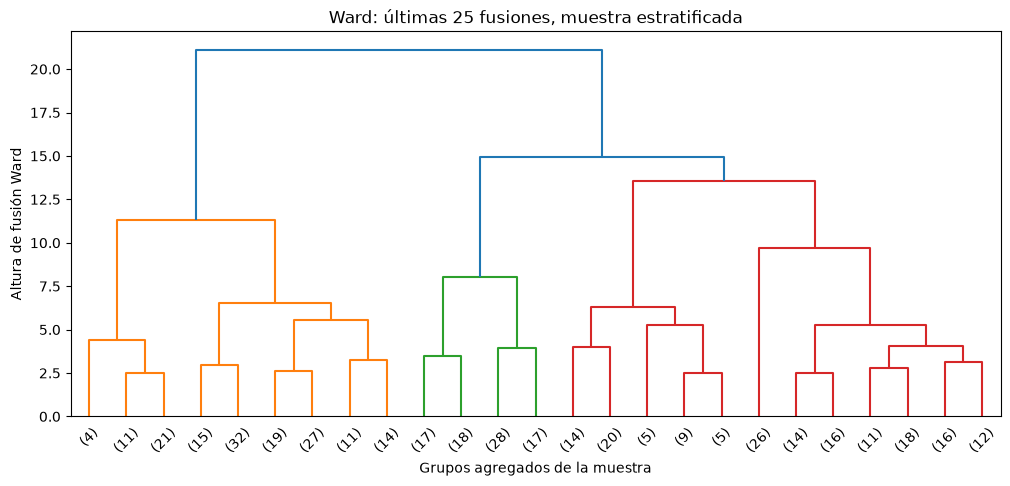

Muestra: 400 | grupos Ward: 4
ARI Ward / KMeans sobre IDs comunes: 0.48312999477516794


label,0,1,2,3
ward_label,,,,
1,118,1,32,3
2,0,0,58,22
3,4,41,8,0
4,19,8,0,86


In [9]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.metrics import adjusted_rand_score

# Toma una muestra de hasta 400 entidades, balanceada por tramo de volumen.
# Así Ward es legible sin convertir la muestra en una estimación de proporciones nacionales.
parts = [g.sort_values("entity_id") for _, g in baseline.groupby("volume_band", observed=True)]
quota = [0] * len(parts)
for _ in range(min(400, len(baseline))):
    candidates = [i for i, g in enumerate(parts) if quota[i] < len(g)]
    chosen = min(candidates, key=lambda i: (quota[i], i))
    quota[chosen] += 1
sample = (
    pd.concat(
        [g.sample(n=q, random_state=42) for g, q in zip(parts, quota, strict=True) if q],
        ignore_index=True,
    )
    .sort_values("entity_id")
    .reset_index(drop=True)
)
# Muestra cuántas entidades existen y cuántas se tomaron de cada tramo.
display(
    pd.DataFrame(
        {
            "tramo": [str(g.volume_band.iloc[0]) for g in parts],
            "poblacion": [len(g) for g in parts],
            "muestra": quota,
        }
    )
)
print("IDs muestreados y variables originales:")
display(
    sample[["entity_id", "volume_band", "award_count", "fraction_0", "fraction_1", "fraction_2"]]
)
# Estandariza la muestra con la misma escala weighted usada por KMeans seleccionado.
cols = meta["scaling"]["columns"]
x_sample = (sample[cols].to_numpy() - np.array(meta["scaling"]["mean"])) / np.array(
    meta["scaling"]["scale"]
)
x_sample[:, 1:] *= meta["scaling"]["weighted_category_factor"]
# Ward une grupos similares paso a paso; el dendrograma muestra las últimas 25 fusiones.
ward_tree = linkage(x_sample, method="ward", metric="euclidean")
plt.figure(figsize=(12, 5))
dendrogram(ward_tree, truncate_mode="lastp", p=25, show_leaf_counts=True)
plt.title("Ward: últimas 25 fusiones, muestra estratificada")
plt.xlabel("Grupos agregados de la muestra")
plt.ylabel("Altura de fusión Ward")
plt.show()
if meta["kmeans_selected"]:
    # Corta Ward en cuatro grupos solo para compararlo con KMeans; no declara cuatro grupos reales.
    sample["ward_label"] = fcluster(
        ward_tree, t=int(meta["kmeans_selected"]["k"]), criterion="maxclust"
    )
    comparison = sample.merge(k_selected[["entity_id", "label"]], on="entity_id")
    print("Muestra:", len(sample), "| grupos Ward:", sample.ward_label.nunique())
    print(
        "ARI Ward / KMeans sobre IDs comunes:",
        adjusted_rand_score(comparison.ward_label, comparison.label),
    )
    # La tabla muestra cómo se cruzan las etiquetas Ward y KMeans.
    display(pd.crosstab(comparison.ward_label, comparison.label))


### Lectura Ward :v

Ward organiza una muestra balanceada de 400 entidades en un árbol: ramas cercanas representan perfiles más parecidos. La muestra tiene 100 entidades de cada tramo de volumen para que los casos de volumen alto no dominen la vista.

El ARI de aproximadamente 0.48 frente a KMeans muestra coincidencia parcial: ambos métodos detectan cierta estructura, pero no producen exactamente los mismos grupos. Ward se usa como contraste descriptivo, no como reemplazo automático de KMeans.


## 6. Estabilidad de HDBSCAN por remuestreo

Cinco subconjuntos del 80 % se comparan con la ejecución completa solo en los ID compartidos. Reportamos ARI incluyendo el ruido y ARI restringido a los puntos asignados en ambas ejecuciones, junto con el tamaño de esa intersección. La escala permanece ajustada a toda la población: la estabilidad es condicional al preprocesamiento. HDBSCAN puede variar entre plataformas y los vectores idénticos hacen sensible la construcción de densidades.

In [10]:
import hdbscan
from threadpoolctl import threadpool_limits

if meta["hdbscan_selected"]:
    hconfig = meta["hdbscan_selected"]
    # Ordena entidades y vuelve a aplicar la misma escala weighted de la corrida principal.
    ordered = features.sort_values("entity_id").reset_index(drop=True)
    x_all = (ordered[cols].to_numpy() - np.array(meta["scaling"]["mean"])) / np.array(
        meta["scaling"]["scale"]
    )
    x_all[:, 1:] *= meta["scaling"]["weighted_category_factor"]
    # Guarda las etiquetas de la corrida completa como referencia.
    reference = (
        ordered[["entity_id"]]
        .merge(h_selected[["entity_id", "label"]], on="entity_id", validate="one_to_one")
        .label.to_numpy()
    )
    stability_h = []
    # Repite HDBSCAN sobre cinco muestras aleatorias del 80 %.
    with threadpool_limits(limits=1):
        for seed in (1, 7, 21, 42, 100):
            rng = np.random.default_rng(seed)
            idx = np.sort(rng.choice(len(ordered), size=int(0.8 * len(ordered)), replace=False))
            labels = hdbscan.HDBSCAN(
                min_cluster_size=int(hconfig["min_cluster_size"]),
                min_samples=int(hconfig["min_samples"]),
                core_dist_n_jobs=1,
            ).fit_predict(x_all[idx])
            ref = reference[idx]
            both = (ref != -1) & (labels != -1)
            stability_h.append(
                {
                    "seed": seed,
                    "n": len(idx),
                    "noise_fraction": float((labels == -1).mean()),
                    "ari_including_noise": adjusted_rand_score(ref, labels),
                    "both_assigned": int(both.sum()),
                    "ari_both_assigned": adjusted_rand_score(ref[both], labels[both])
                    if both.sum() > 1
                    else None,
                }
            )
    # ARI incluye ruido en la primera medida; la segunda usa solo entidades asignadas en ambas corridas.
    display(pd.DataFrame(stability_h))


c:\Users\HP\Desktop\2026-02\DataMining\Proyecto2\.venv312\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\HP\Desktop\2026-02\DataMining\Proyecto2\.venv312\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\HP\Desktop\2026-02\DataMining\Proyecto2\.venv312\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\HP\Desktop\2026-02\DataMining\Proyecto2\.venv312\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\HP\Desktop\2026-02\DataMining\Proyecto2\.venv312\Lib\site-packages\

,seed,n,noise_fraction,ari_including_noise,both_assigned,ari_both_assigned
0,1,2204,0.445554,0.530630,992,0.451485
1,7,2204,0.418330,0.527472,1020,0.456876
2,21,2204,0.376134,0.420196,1013,0.357848
3,42,2204,0.392922,0.503980,1032,0.506852
4,100,2204,0.535844,0.669160,922,0.838402


### Estabilidad de HDBSCAN

Se repite HDBSCAN en muestras del 80 %. La fracción de ruido y el ARI cambian entre repeticiones, por lo que los grupos densos son menos estables que los de KMeans.

La conclusión es prudente: HDBSCAN aporta señales exploratorias de densidad y posibles casos atípicos, pero sus etiquetas no se tratan como segmentos definitivos.


## 7. Lectura y límites

- La composición de categorías distingue perfiles dentro de volúmenes similares, pero las tres proporciones son dependientes y no representan gasto.
- HDBSCAN describe densidad en estas cuatro variables; los vectores repetidos y los cambios de escala, parámetros o muestra afectan sus etiquetas. La silueta sobre asignados no es directamente comparable con la silueta de toda la población.
- Ward solo describe la muestra estratificada; el corte se hizo para una comparación exploratoria con KMeans.
- Las señales de distancia y ruido no implican fraude, desempeño ni responsabilidad. La cobertura de la fuente y la identidad no resuelta limitan las conclusiones; consultar el reporte de la Parte II para las cifras e interpretación verificadas.

**Referencia de la corrida Windows:** Ward y KMeans alcanzaron ARI 0,483 en 400 ID. El grupo KMeans de mayor volumen concentró 672 de sus 968 entidades en el tramo superior; los otros tres separan perfiles con medianas de 5–6 adjudicaciones según su composición. HDBSCAN obtuvo ARI de 0,420–0,669 en remuestreos con ruido incluido. De 29 candidatos por distancia, 14 coincidieron con ruido. Las cifras dependen de los datos y del entorno; el reporte conserva el contexto y las diferencias observadas con Docker.